In [61]:
import pandas as pd

In [62]:
df=pd.read_csv('C:/Users/Ram/Desktop/AIAP Foundation/Bonus regression/bonus regression/data/regression_bonus_practice_data.csv')

### Preliminary Data Exploration

In [63]:
 
df.head()

,index,number_of_siblings,direct_admission,CCA,learning_style,student_id,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color
0,0,0,Yes,Sports,Visual,ACN2BE,Female,No,69.0,14.0,2.0,16.0,10.0,91.0,22:00,6:00,private transport,yellow
1,1,2,No,Sports,Auditory,FGXIIZ,Female,No,47.0,4.0,19.0,16.0,7.0,94.0,22:30,6:30,private transport,green
2,2,0,Yes,NaN,Visual,B9AI9F,Male,No,85.0,14.0,2.0,15.0,8.0,92.0,22:30,6:30,private transport,white
3,3,1,No,Clubs,Auditory,FEVM1T,Female,Yes,64.0,2.0,20.0,15.0,18.0,NaN,21:00,5:00,public transport,yellow
4,4,0,No,Sports,Auditory,AXZN2E,Male,No,66.0,24.0,3.0,16.0,7.0,95.0,21:30,5:30,public transport,yellow


In [64]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15900 entries, 0 to 15899
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   index               15900 non-null  int64  
 1   number_of_siblings  15900 non-null  int64  
 2   direct_admission    15900 non-null  str    
 3   CCA                 12071 non-null  str    
 4   learning_style      15900 non-null  str    
 5   student_id          15900 non-null  str    
 6   gender              15900 non-null  str    
 7   tuition             15900 non-null  str    
 8   final_test          15405 non-null  float64
 9   n_male              15900 non-null  float64
 10  n_female            15900 non-null  float64
 11  age                 15900 non-null  float64
 12  hours_per_week      15900 non-null  float64
 13  attendance_rate     15122 non-null  float64
 14  sleep_time          15900 non-null  str    
 15  wake_time           15900 non-null  str    
 16  mode_of_transpo

The Non-Null result shows that there are some missing values in the columns 'CCA', 'final_test' and 'attendance_rate'. Now, we can check the no. of missing entries as below.

In [65]:
df.isnull().sum()

index                    0
number_of_siblings       0
direct_admission         0
CCA                   3829
learning_style           0
student_id               0
gender                   0
tuition                  0
final_test             495
n_male                   0
n_female                 0
age                      0
hours_per_week           0
attendance_rate        778
sleep_time               0
wake_time                0
mode_of_transport        0
bag_color                0
dtype: int64

The result shows that the column 'CCA' has 3829, 'final_test' has 495 and 'attendance_rate' has 778 missing values, respectively.

The rows with the missing value of 'final_test' and 'attendance_rate' needs to be dropped, because the values cannot be updated in the empty cells based on aany valid reason of relationship.

In [66]:
# Drop only rows where the final_test score, attendance_rate are missing
df = df.dropna(subset=['final_test', 'attendance_rate'])
df['final_test']=pd.to_numeric(df['final_test'], errors='coerce')
df['attendance_rate']=pd.to_numeric(df['attendance_rate'], errors='coerce') 

In [67]:
df.isnull().sum()

index                    0
number_of_siblings       0
direct_admission         0
CCA                   3515
learning_style           0
student_id               0
gender                   0
tuition                  0
final_test               0
n_male                   0
n_female                 0
age                      0
hours_per_week           0
attendance_rate          0
sleep_time               0
wake_time                0
mode_of_transport        0
bag_color                0
dtype: int64

Check whether the column 'CCA' has any value equal to 'NONE'.

In [299]:
df[df['CCA'].isin(['NONE'])]

,index,number_of_siblings,direct_admission,CCA,learning_style,student_id,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color
312,312,0,No,NONE,Auditory,VC9PM2,Female,Yes,89.0,15.0,7.0,16.0,7.0,92.0,23:00,7:00,walk,blue
647,647,0,Yes,NONE,Visual,VTH6BH,Female,No,91.0,1.0,19.0,15.0,7.0,100.0,22:00,6:00,private transport,blue
667,667,0,Yes,NONE,Visual,FC2F9A,Male,Yes,81.0,10.0,7.0,16.0,9.0,98.0,21:30,5:30,public transport,red
857,857,0,No,NONE,Visual,MKWV6I,Male,No,74.0,17.0,10.0,15.0,10.0,95.0,22:30,6:30,private transport,blue
935,935,0,No,NONE,Auditory,JHU7JE,Male,No,65.0,17.0,4.0,16.0,8.0,92.0,23:00,7:00,walk,blue
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15510,15510,0,No,NONE,Auditory,BI7UT9,Female,Yes,82.0,22.0,0.0,16.0,7.0,97.0,21:00,5:00,public transport,yellow
15521,15521,0,No,NONE,Visual,YDC6BD,Male,No,82.0,23.0,1.0,16.0,6.0,98.0,21:30,5:30,public transport,yellow
15670,15670,0,No,NONE,Visual,56IT42,Female,Yes,91.0,12.0,11.0,16.0,10.0,96.0,21:00,5:00,public transport,black
15859,15859,1,Yes,NONE,Visual,VI6D9T,Male,Yes,85.0,17.0,5.0,15.0,6.0,93.0,22:00,6:00,private transport,blue


There are 119 rows are having value 'NONE' in the column 'CCA'. 

Now, let the value 'None' and 'NONE' be converted into nan and then it can be filled with the value 'No_CCA'. So it can be considered as a seperate catgeory.

In [300]:
import numpy as np

df['CCA'] = df['CCA'].replace(['None', 'NONE'], np.nan)

#df['CCA'] = df['CCA'].replace({'NONE': 'No_CCA'})

df['CCA'] = df['CCA'].fillna('No_CCA')

In [301]:
df[df['CCA'].isin(['No_CCA'])]

,index,number_of_siblings,direct_admission,CCA,learning_style,student_id,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color
2,2,0,Yes,No_CCA,Visual,B9AI9F,Male,No,85.0,14.0,2.0,15.0,8.0,92.0,22:30,6:30,private transport,white
6,6,2,Yes,No_CCA,Visual,D5WGTI,Male,No,69.0,12.0,3.0,16.0,15.0,93.0,21:30,5:30,public transport,green
17,17,1,No,No_CCA,Auditory,FALLVI,Female,Yes,70.0,26.0,2.0,15.0,10.0,100.0,22:30,6:30,private transport,black
21,21,0,No,No_CCA,Visual,HJ6Y5P,Male,Yes,86.0,17.0,6.0,16.0,8.0,91.0,23:30,6:30,private transport,red
29,29,1,Yes,No_CCA,Auditory,ZGU81D,Male,Yes,88.0,17.0,0.0,15.0,6.0,94.0,21:00,5:00,public transport,black
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15886,15886,0,No,No_CCA,Visual,72YL3P,Male,Yes,89.0,10.0,12.0,15.0,7.0,95.0,22:00,6:00,private transport,blue
15891,15891,1,No,No_CCA,Auditory,LEKMPX,Female,Yes,61.0,8.0,16.0,5.0,16.0,95.0,21:30,5:30,public transport,yellow
15894,15894,0,No,No_CCA,Visual,XT1L7Z,Male,Yes,73.0,16.0,12.0,15.0,14.0,95.0,22:30,6:30,private transport,blue
15896,15896,1,Yes,No_CCA,Auditory,7AMC7S,Male,Yes,85.0,17.0,5.0,16.0,7.0,91.0,22:30,6:30,private transport,white


The total no. of rows 3634 (3515 + 119) are with the value 'No_CCA'. Now, there are no missing value in the column 'CCA'

In [69]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
index,14648.0,7943.148348,4595.738708,0.0,3963.75,7934.5,11926.25,15899.0
number_of_siblings,14648.0,0.886810,0.751882,0.0,0.00,1.0,1.00,2.0
final_test,14648.0,67.146300,13.962471,32.0,56.00,68.0,78.00,100.0
n_male,14648.0,13.867149,6.549461,0.0,10.00,14.0,18.00,31.0
n_female,14648.0,8.927294,6.682224,0.0,4.00,8.0,13.00,31.0
age,14648.0,15.210814,1.767094,-5.0,15.00,15.0,16.00,16.0
hours_per_week,14648.0,10.320999,4.464532,0.0,7.00,9.0,14.00,20.0
attendance_rate,14648.0,93.265770,7.986489,40.0,92.00,95.0,97.00,100.0


The above result shows that there are certain negative values in the column 'age'. 'final_test' values range from 32 to 100 and 'attendance_rate' values range from 40 to 100.

In [70]:
df.duplicated().sum()

np.int64(0)

Need to check the duplicated based on 'student_id' only. The following script will check the duplication based on 'studen_id'.

In [304]:
df.duplicated(subset= 'student_id').sum()

np.int64(763)

In [305]:
df[df.duplicated(subset= 'student_id', keep=False)].sort_values(by=list(df.columns))

,index,number_of_siblings,direct_admission,CCA,learning_style,student_id,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color
4,4,0,No,Sports,Auditory,AXZN2E,Male,No,66.0,24.0,3.0,16.0,7.0,95.0,21:30,5:30,public transport,yellow
12,12,0,No,Sports,Visual,T4U89N,Male,Yes,85.0,14.0,4.0,16.0,8.0,95.0,23:00,7:00,walk,green
14,14,0,Yes,Arts,Auditory,G0JBVS,Female,Yes,75.0,14.0,2.0,15.0,15.0,98.0,22:30,6:30,private transport,white
21,21,0,No,No_CCA,Visual,HJ6Y5P,Male,Yes,86.0,17.0,6.0,16.0,8.0,91.0,23:30,6:30,private transport,red
24,24,0,No,Arts,Visual,PQ059G,Male,No,77.0,23.0,4.0,15.0,6.0,93.0,21:00,5:00,public transport,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15868,15868,1,No,Clubs,Visual,1FKAEF,Male,No,61.0,20.0,6.0,16.0,6.0,95.0,21:30,5:30,public transport,yellow
15871,15871,1,No,Arts,Visual,Z9YY3M,Female,No,52.0,25.0,5.0,15.0,18.0,98.0,22:00,6:00,private transport,black
15875,15875,0,No,Clubs,Auditory,MCO9BB,Female,Yes,68.0,17.0,4.0,16.0,13.0,99.0,22:00,6:00,private transport,red
15886,15886,0,No,No_CCA,Visual,72YL3P,Male,Yes,89.0,10.0,12.0,15.0,7.0,95.0,22:00,6:00,private transport,blue


So, the duplicated rows based on 'student_id' needs to be dropped.

In [306]:
df.drop_duplicates(subset= 'student_id', inplace=True)

In [307]:
df.duplicated(subset= 'student_id').sum()

np.int64(0)

## Univariate Analysis

In [308]:
import seaborn as sns
import matplotlib.pyplot as plt

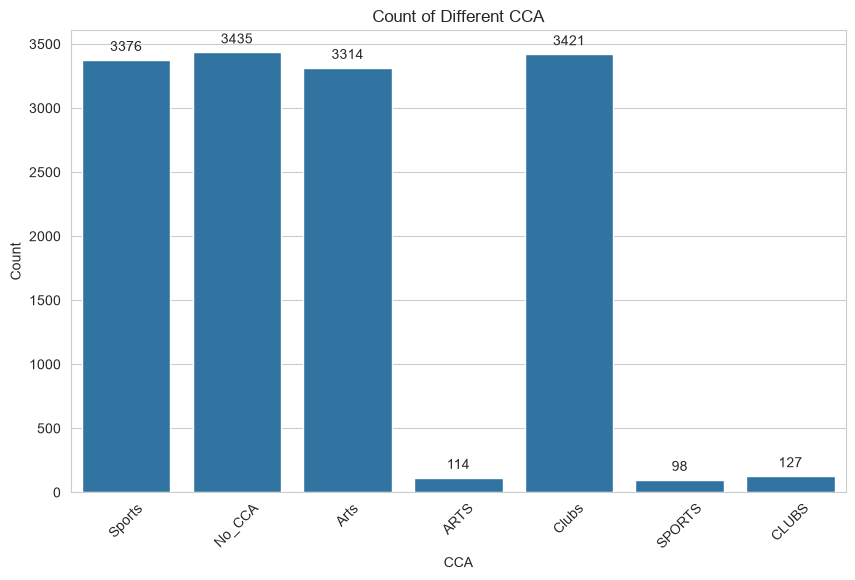

In [309]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for gender with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='CCA', data=df)
plt.title('Count of Different CCA')
plt.xlabel('CCA')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

It shows that the column 'CCA' has the value in fully capital letters. It needs to be changed and standardized.

In [310]:
df['CCA'] = df['CCA'].replace({'ARTS': 'Arts', 'SPORTS': 'Sports', 'CLUBS': 'Clubs'})

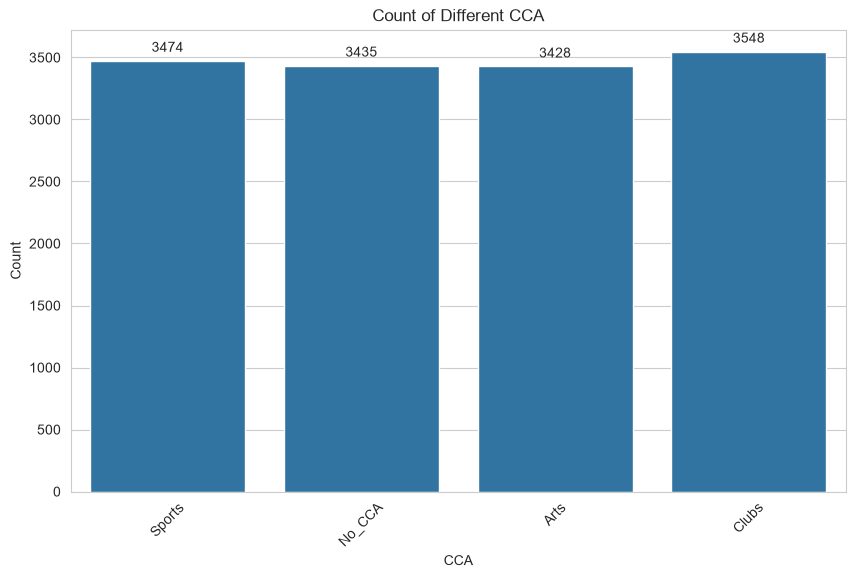

In [311]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for gender with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='CCA', data=df)
plt.title('Count of Different CCA')
plt.xlabel('CCA')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

Check the value of the column 'tuition'.

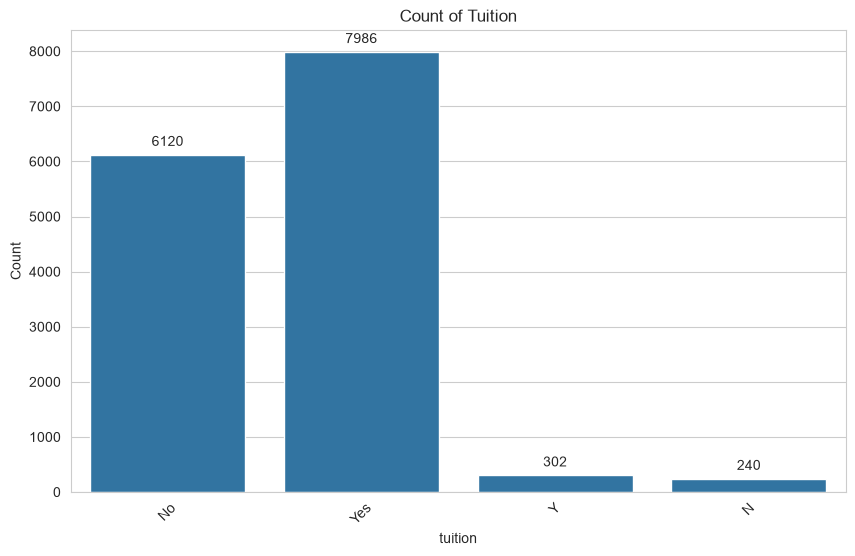

In [72]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for gender with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='tuition', data=df)
plt.title('Count of Tuition')
plt.xlabel('tuition')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

Replace the value 'Y' to 'Yes' and 'N' to 'No'.

In [74]:
df['tuition'] = df['tuition'].replace({'Y': 'Yes', 'N': 'No'})

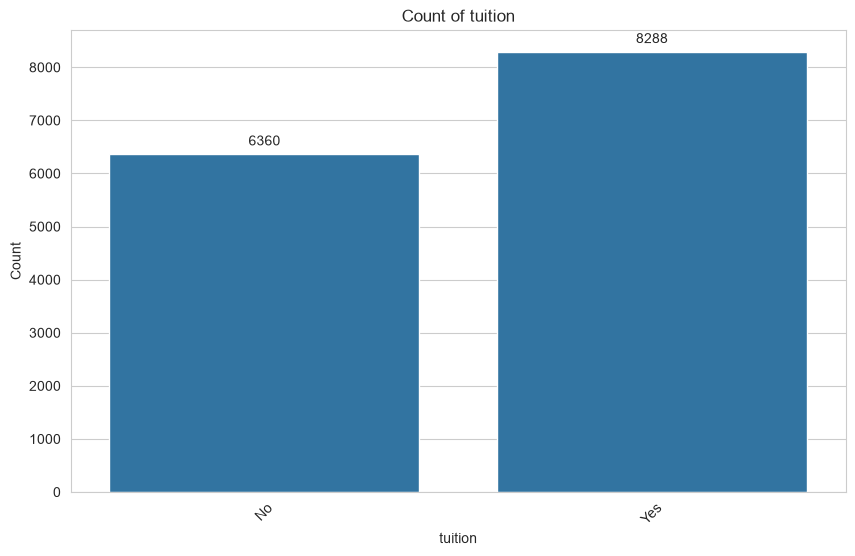

In [75]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for gender with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='tuition', data=df)
plt.title('Count of tuition')
plt.xlabel('tuition')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

Columns with the values 'Yes' or 'No' and 'male' or 'female' should be changed to 1, 0. The binary text columns will be changed to numerical columns.

In [ ]:
# Convert binary text columns directly into 0 and 1
df['gender'] = df['gender'].astype(str).str.lower().map({'male': 1, 'female': 0})
df['tuition'] = df['tuition'].astype(str).str.lower().map({'Yes': 1, 'No': 0})
df['direct_admission'] = df['direct_admission'].astype(str).str.lower().map({'Yes': 1, 'No': 0})

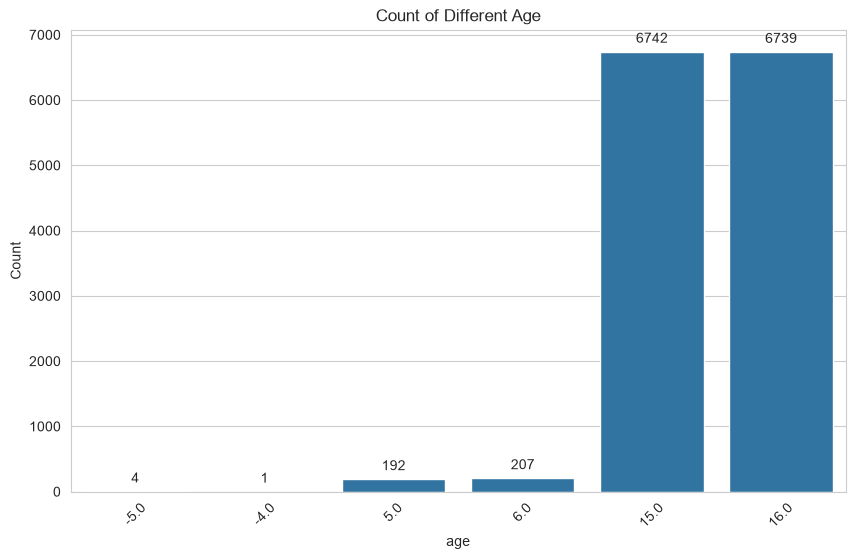

In [316]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for gender with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='age', data=df)
plt.title('Count of Different Age')
plt.xlabel('age')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

For O Level student the minimum age could either 15 or 16 only. It won't be < 15 and won't be negative age. So, there is typo errors and this should be rectified. It is assumed that it could have been entered -5, 5, and 6 instead of 15 or 16 wrongly, so these should be replaced -5, 5 as 15 and 6 as 16. We can drop the row where age value is -4.

In [317]:
# 1. Drop rows where age is exactly -4
df = df[df["age"] != -4]

# 2. Fix the typos for -5, 5, and 6 (Optional but highly recommended)
df["age"] = df["age"].replace({-5: 15, 5: 15, 6: 16})
 


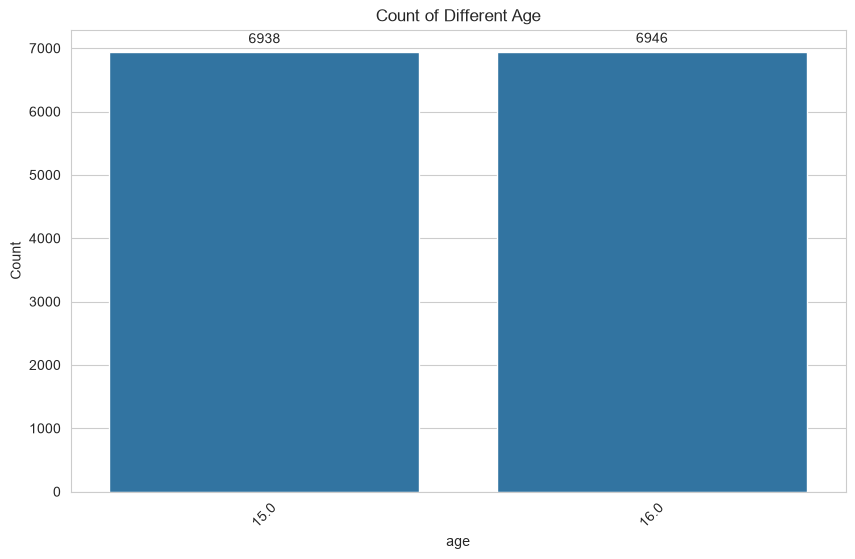

In [318]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for gender with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='age', data=df)
plt.title('Count of Different Age')
plt.xlabel('age')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

In [87]:
# 1. Convert the string times (like '22.30') into an official datetime format.
# We map them to a baseline dummy date (e.g., 1900-01-01) just to do the time math.
sleep_datetime = pd.to_datetime(
    df["sleep_time"].str.replace(".", ":", regex=False), format="%H:%M"
)
wake_datetime = pd.to_datetime(
    df["wake_time"].str.replace(".", ":", regex=False), format="%H:%M"
)

# 2. Subtract the two datetime series to get the raw time difference (Duration)
raw_duration = wake_datetime - sleep_datetime

# 3. Convert that time difference into numeric hours (e.g., 7.5)
df["duration_hours"] = raw_duration.dt.total_seconds() / 3600

# 4. Fix Midnight Crossovers
# If the sleep time was 22:00 and wake was 05:30, the math results in a negative number.
# If it's negative, we add 24 hours to get the real duration.
df["duration_hours"] = np.where(
    df["duration_hours"] < 0, df["duration_hours"] + 24, df["duration_hours"]
)

# Your 'df' now safely contains all original 18 columns PLUS the new 'duration_hours' column!
df.head()


,index,number_of_siblings,direct_admission,CCA,learning_style,student_id,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color,total_class_size,duration_hours
0,0,0,Yes,Sports,Visual,ACN2BE,Female,No,69.0,14.0,2.0,16.0,10.0,91.0,22:00,6:00,private transport,yellow,16.0,8.0
1,1,2,No,Sports,Auditory,FGXIIZ,Female,No,47.0,4.0,19.0,16.0,7.0,94.0,22:30,6:30,private transport,green,23.0,8.0
2,2,0,Yes,NaN,Visual,B9AI9F,Male,No,85.0,14.0,2.0,15.0,8.0,92.0,22:30,6:30,private transport,white,16.0,8.0
4,4,0,No,Sports,Auditory,AXZN2E,Male,No,66.0,24.0,3.0,16.0,7.0,95.0,21:30,5:30,public transport,yellow,27.0,8.0
5,5,0,No,Arts,Visual,BA6R14,Female,No,57.0,9.0,12.0,15.0,11.0,96.0,22:30,6:30,private transport,red,21.0,8.0


In [320]:
# Combines n_male and n_female into a comprehensive single layout
if "n_male" in df.columns and "n_female" in df.columns:
    df["total_class_size"] = df["n_male"] + df["n_female"]

df.head()

,index,number_of_siblings,direct_admission,CCA,learning_style,student_id,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color,duration_hours,total_class_size
0,0,0,1,Sports,Visual,ACN2BE,0,0,69.0,14.0,2.0,16.0,10.0,91.0,22:00,6:00,private transport,yellow,8.0,16.0
1,1,2,0,Sports,Auditory,FGXIIZ,0,0,47.0,4.0,19.0,16.0,7.0,94.0,22:30,6:30,private transport,green,8.0,23.0
2,2,0,1,No_CCA,Visual,B9AI9F,1,0,85.0,14.0,2.0,15.0,8.0,92.0,22:30,6:30,private transport,white,8.0,16.0
4,4,0,0,Sports,Auditory,AXZN2E,1,0,66.0,24.0,3.0,16.0,7.0,95.0,21:30,5:30,public transport,yellow,8.0,27.0
5,5,0,0,Arts,Visual,BA6R14,0,0,57.0,9.0,12.0,15.0,11.0,96.0,22:30,6:30,private transport,red,8.0,21.0


In [321]:
columns_to_drop = ['student_id', 'mode_of_transport', 'bag_color', 'sleep_time', 'wake_time', 'n_male', 'n_female', 'index']
df = df.drop(columns =  columns_to_drop, errors='ignore')
df.head()

,number_of_siblings,direct_admission,CCA,learning_style,gender,tuition,final_test,age,hours_per_week,attendance_rate,duration_hours,total_class_size
0,0,1,Sports,Visual,0,0,69.0,16.0,10.0,91.0,8.0,16.0
1,2,0,Sports,Auditory,0,0,47.0,16.0,7.0,94.0,8.0,23.0
2,0,1,No_CCA,Visual,1,0,85.0,15.0,8.0,92.0,8.0,16.0
4,0,0,Sports,Auditory,1,0,66.0,16.0,7.0,95.0,8.0,27.0
5,0,0,Arts,Visual,0,0,57.0,15.0,11.0,96.0,8.0,21.0


### Data Splitting

In [322]:
# Separate the data into features and target
X = df.drop(columns='final_test')
y = df['final_test']

In [323]:
X.head()

,number_of_siblings,direct_admission,CCA,learning_style,gender,tuition,age,hours_per_week,attendance_rate,duration_hours,total_class_size
0,0,1,Sports,Visual,0,0,16.0,10.0,91.0,8.0,16.0
1,2,0,Sports,Auditory,0,0,16.0,7.0,94.0,8.0,23.0
2,0,1,No_CCA,Visual,1,0,15.0,8.0,92.0,8.0,16.0
4,0,0,Sports,Auditory,1,0,16.0,7.0,95.0,8.0,27.0
5,0,0,Arts,Visual,0,0,15.0,11.0,96.0,8.0,21.0


In [324]:
from sklearn.model_selection import train_test_split

# Split the data into training (80%) and test-validation (20%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)

# Split the test-validation set (20%) into validation (10%) and test (10%) sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

In [325]:
# Display the shapes of the splits to verify
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (11107, 11) (11107,)
Validation set shape: (1388, 11) (1388,)
Test set shape: (1389, 11) (1389,)


In [326]:
X_train.head()

,number_of_siblings,direct_admission,CCA,learning_style,gender,tuition,age,hours_per_week,attendance_rate,duration_hours,total_class_size
4293,1,0,Clubs,Visual,0,1,16.0,11.0,98.0,8.0,24.0
9021,1,0,Clubs,Auditory,0,0,15.0,6.0,96.0,8.0,29.0
8710,1,1,No_CCA,Auditory,0,1,16.0,9.0,95.0,8.0,17.0
9888,1,0,Arts,Auditory,0,1,16.0,6.0,93.0,8.0,24.0
1478,1,1,Arts,Auditory,0,0,15.0,10.0,99.0,8.0,29.0


In [327]:
y_train.head()

4293    57.0
9021    50.0
8710    87.0
9888    56.0
1478    48.0
Name: final_test, dtype: float64

#### Data Scalling

In [328]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Define numerical features to be standardized
numerical_features = ['number_of_siblings', 'age', 'hours_per_week', 'attendance_rate', 'duration_hours', 'total_class_size']

# Create a numerical transformer pipeline
numerical_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

#### Data Encoding

In [329]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Define nominal features to be one-hot encoded
nominal_features = ['CCA', 'learning_style']

# Define passthrough features that will not be transformed
passthrough_features = ['direct_admission', 'gender', 'tuition']

# Create a nominal transformer pipeline
nominal_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

#### Combined Features Scaling and Encoding

In [330]:
from sklearn.compose import ColumnTransformer

# Combine transformers into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('nom', nominal_transformer, nominal_features),
        ('pass', 'passthrough', passthrough_features) # Pass through the direct admission, etc feature without transformation
    ],
    remainder='passthrough',
    n_jobs=-1
    )

In [331]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",-1
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feat

In [332]:
ColumnTransformer(n_jobs=-1, remainder='passthrough',
    transformers=[('num',
        Pipeline(steps=[('scaler', StandardScaler())]),
        ['number_of_siblings', 'age', 'hours_per_week', 'attendance_rate',
        'duration_hours', 'total_class_size']),
    ('nom',
        Pipeline(steps=[('onehot', OneHotEncoder())]),
        ['CCA', 'learning_style']),
    ('pass', 'passthrough', ['direct_admission', 'gender', 'tuition'])])

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",-1
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feat

In [333]:
from sklearn.linear_model import LinearRegression

# Create the pipeline with a linear regression model
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

In [334]:
Pipeline(steps=[('preprocessor',
    ColumnTransformer(n_jobs=-1, remainder='passthrough',
        transformers=[('num',
            Pipeline(steps=[('scaler', StandardScaler())]),
            ['number_of_siblings', 'age', 'hours_per_week', 'attendance_rate',
            'duration_hours', 'total_class_size']),
        ('nom',
            Pipeline(steps=[('onehot', OneHotEncoder())]),
            ['CCA', 'learning_style']),
        ('pass', 'passthrough', ['direct_admission', 'gender', 'tuition'])])),
    ('regressor', LinearRegression())])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"n_jobs n_jobs: int, default=NoneNumber of j

#### Training and Validation of the First Machine Learning Model

In [335]:
# Fit the pipeline to the training data
lr_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = lr_pipeline.predict(X_val)

#### Predicted Value

In [336]:
y_val_pred

array([62.94171308, 71.67800369, 75.31586162, ..., 66.28903076,
       51.15577743, 80.89410067], shape=(1388,))

In [337]:
print("Test set shape:", X_test.shape, y_test.shape)

Test set shape: (1389, 11) (1389,)


#### Model Evaluation

In [338]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

# Calculate regression metrics for validation set
val_mae = mean_absolute_error(y_val, y_val_pred)
val_mse = mean_squared_error(y_val, y_val_pred)
val_rmse = root_mean_squared_error(y_val, y_val_pred)  # RMSE is the square root of MSE
val_r2 = r2_score(y_val, y_val_pred)

# Display the metrics
print(f"Validation MAE: {val_mae}")
print(f"Validation MSE: {val_mse}")
print(f"Validation RMSE: {val_rmse}")
print(f"Validation R2: {val_r2}")

Validation MAE: 7.303362487615148
Validation MSE: 83.12574066493487
Validation RMSE: 9.117331883009133
Validation R2: 0.5904162951869201


#### Ridge regression

In [339]:
from sklearn.linear_model import Ridge

# Fit Ridge Regression with lambda (alpha in scikit-learn)
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1))
])
ridge_pipeline.fit(X_train, y_train)

# Predict on the validation set with Ridge Regression
y_val_pred_ridge = ridge_pipeline.predict(X_val)

# Calculate regression metrics for validation set with Ridge Regression
val_mae_ridge = mean_absolute_error(y_val, y_val_pred_ridge)
val_mse_ridge = mean_squared_error(y_val, y_val_pred_ridge)
val_rmse_ridge = root_mean_squared_error(y_val, y_val_pred_ridge)  # RMSE is the square root of MSE
val_r2_ridge = r2_score(y_val, y_val_pred_ridge)

# Display the metrics for Ridge Regression
print("Ridge Regression Metrics:")
print(f"Ridge Validation MAE: {val_mae_ridge}")
print(f"Ridge Validation MSE: {val_mse_ridge}")
print(f"Ridge Validation RMSE: {val_rmse_ridge}")
print(f"Ridge Validation R²: {val_r2_ridge}")

Ridge Regression Metrics:
Ridge Validation MAE: 7.3034226736192895
Ridge Validation MSE: 83.12611323999808
Ridge Validation RMSE: 9.117352315228258
Ridge Validation R²: 0.5904144594056869


#### Extracting Coefficients - Linear and Ridge

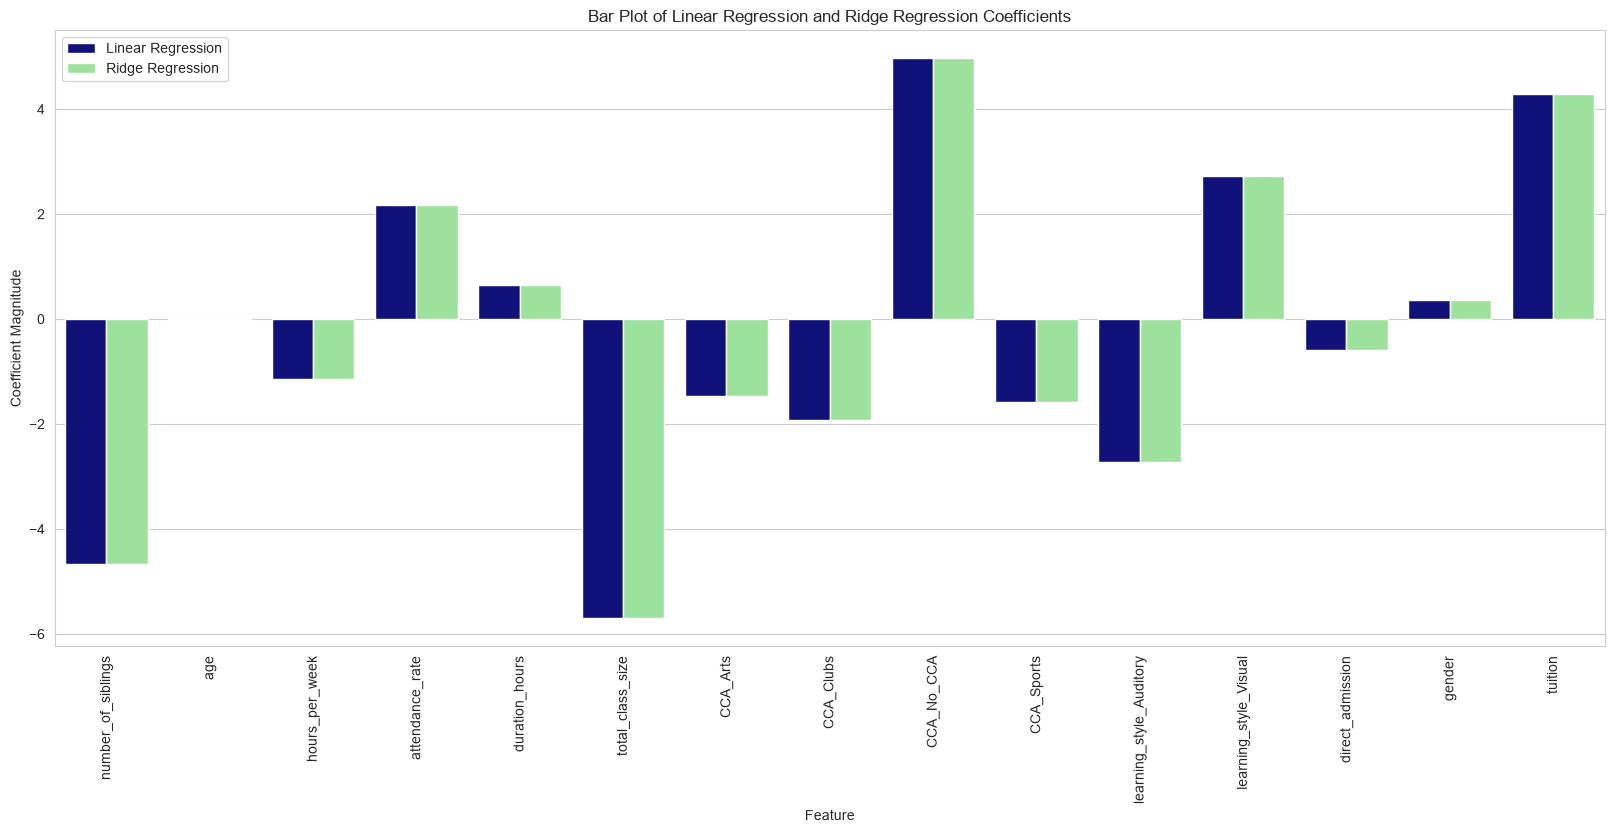

In [340]:
# Extract the coefficients of the linear regression model
lr_coefs = lr_pipeline.named_steps['regressor'].coef_

# Extract the coefficients of the ridge regression model
ridge_coefs = ridge_pipeline.named_steps['regressor'].coef_

# Assuming feature_names contains the names of the features after preprocessing
feature_names = (
    numerical_features +
    list(ridge_pipeline.named_steps['preprocessor'].transformers_[1][1].named_steps['onehot'].get_feature_names_out(nominal_features)) +
    passthrough_features
)

# Create a DataFrame for plotting
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Linear Regression': lr_coefs,
    'Ridge Regression': ridge_coefs
})

# Melt the DataFrame to long format for seaborn
coef_df = coef_df.melt(id_vars='Feature', var_name='Model', value_name='Coefficient')

# Plotting the coefficients with seaborn
plt.figure(figsize=(20, 8))
sns.barplot(data=coef_df, x='Feature', y='Coefficient', hue='Model', palette=['darkblue', 'lightgreen'])

plt.xlabel('Feature')
plt.ylabel('Coefficient Magnitude')
plt.title('Bar Plot of Linear Regression and Ridge Regression Coefficients')
plt.xticks(rotation=90)
plt.grid(True, axis='y')
plt.legend(loc='upper left')
plt.show()

##### Lasso Regression

In [341]:
from sklearn.linear_model import Lasso

# Fit Lasso Regression with default alpha
lasso_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Lasso(alpha=1))
])
lasso_pipeline.fit(X_train, y_train)

# Predict on the validation set with Lasso Regression
y_val_pred_lasso = lasso_pipeline.predict(X_val)

# Calculate regression metrics for validation set with Lasso Regression
val_mae_lasso = mean_absolute_error(y_val, y_val_pred_lasso)
val_mse_lasso = mean_squared_error(y_val, y_val_pred_lasso)
val_rmse_lasso = root_mean_squared_error(y_val, y_val_pred_lasso)  # RMSE is the square root of MSE
val_r2_lasso = r2_score(y_val, y_val_pred_lasso)

# Display the metrics for Lasso Regression
print("Lasso Regression Metrics:")
print(f"Lasso Validation MAE: {val_mae_lasso}")
print(f"Lasso Validation MSE: {val_mse_lasso}")
print(f"Lasso Validation RMSE: {val_rmse_lasso}")
print(f"Lasso Validation R²: {val_r2_lasso}")

Lasso Regression Metrics:
Lasso Validation MAE: 7.978994320729395
Lasso Validation MSE: 97.33006243725623
Lasso Validation RMSE: 9.86559995323428
Lasso Validation R²: 0.5204276407782307


##### Extract Coefficients - Linear and Lasso

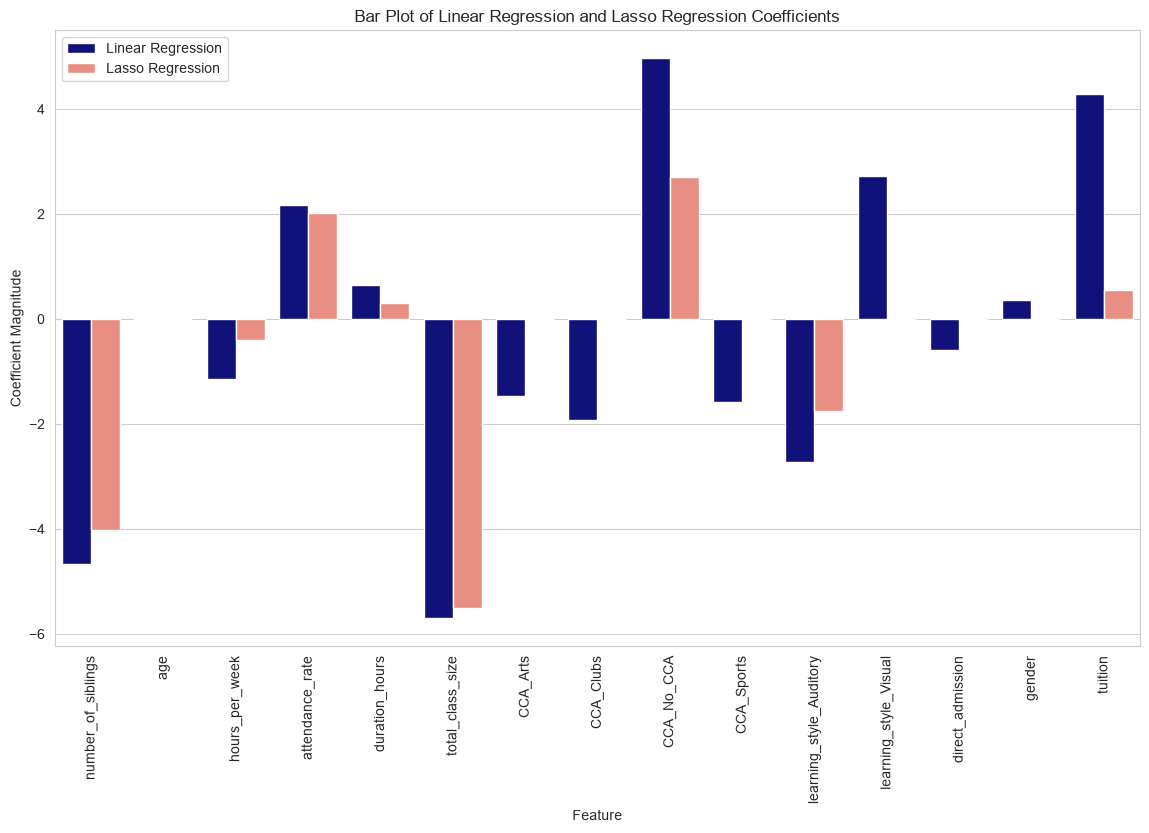

In [342]:
# Extract the coefficients of the linear and lasso regression models
lr_coefs = lr_pipeline.named_steps['regressor'].coef_
lasso_coefs = lasso_pipeline.named_steps['regressor'].coef_

# Extract feature names after preprocessing
feature_names = (
    numerical_features +
    list(preprocessor.transformers_[1][1].named_steps['onehot'].get_feature_names_out(nominal_features)) +
    passthrough_features
)

# Create a DataFrame for plotting
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Linear Regression': lr_coefs,
    'Lasso Regression': lasso_coefs
})

# Melt the DataFrame to long format for seaborn
coef_df = coef_df.melt(id_vars='Feature', var_name='Model', value_name='Coefficient')

# Plotting the coefficients with seaborn
plt.figure(figsize=(14, 8))
sns.barplot(data=coef_df, x='Feature', y='Coefficient', hue='Model', palette=['darkblue', 'salmon'])

plt.xlabel('Feature')
plt.ylabel('Coefficient Magnitude')
plt.title('Bar Plot of Linear Regression and Lasso Regression Coefficients')
plt.xticks(rotation=90)
plt.grid(True, axis='y')
plt.legend(loc='upper left')
plt.show()

### Hyperparmeter Tuning

- ##### GridSearchCV

In [343]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'regressor__alpha': [0.1, 1, 10, 100, 1000],
    'regressor__fit_intercept': [True, False]
}

# Create the pipeline with a ridge regression model
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge())
])

# Create the pipeline with a lasso regression model
lasso_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Lasso())
])

# Perform grid search with cross-validation for Ridge regression
ridge_grid_search = GridSearchCV(ridge_pipeline, param_grid, cv=5, scoring='r2', n_jobs=-1)
ridge_grid_search.fit(X_train, y_train)

# Perform grid search with cross-validation for Lasso regression
lasso_grid_search = GridSearchCV(lasso_pipeline, param_grid, cv=5, scoring='r2', n_jobs=-1)
lasso_grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...r', Lasso())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'regressor__alpha': [0.1, 1, ...], 'regressor__fit_intercept': [True, False]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbo

In [344]:
# Print the best parameters found by grid search for Ridge regression
print("Best Ridge parameters:", ridge_grid_search.best_params_)

# Print the best parameters found by grid search for Lasso regression
print("Best Lasso parameters:", lasso_grid_search.best_params_)

Best Ridge parameters: {'regressor__alpha': 10, 'regressor__fit_intercept': True}
Best Lasso parameters: {'regressor__alpha': 0.1, 'regressor__fit_intercept': False}


##### Evaluation of the best Ridge/Lasso model on the Validation set

In [345]:
# Evaluate the best Ridge model on the validation set
best_ridge_model = ridge_grid_search.best_estimator_
y_val_pred_ridge = best_ridge_model.predict(X_val)

# Calculate regression metrics for validation set for Ridge
val_mae_ridge = mean_absolute_error(y_val, y_val_pred_ridge)
val_mse_ridge = mean_squared_error(y_val, y_val_pred_ridge)
val_rmse_ridge = root_mean_squared_error(y_val, y_val_pred_ridge)  # RMSE is the square root of MSE
val_r2_ridge = r2_score(y_val, y_val_pred_ridge)

print("Best Ridge Regression Metrics:")
print(f"Ridge Validation MAE: {val_mae_ridge}")
print(f"Ridge Validation MSE: {val_mse_ridge}")
print(f"Ridge Validation RMSE: {val_rmse_ridge}")
print(f"Ridge Validation R²: {val_r2_ridge}")

# Evaluate the best Lasso model on the validation set
best_lasso_model = lasso_grid_search.best_estimator_
y_val_pred_lasso = best_lasso_model.predict(X_val)

# Calculate regression metrics for validation set for Lasso
val_mae_lasso = mean_absolute_error(y_val, y_val_pred_lasso)
val_mse_lasso = mean_squared_error(y_val, y_val_pred_lasso)
val_rmse_lasso = root_mean_squared_error(y_val, y_val_pred_lasso)  # RMSE is the square root of MSE
val_r2_lasso = r2_score(y_val, y_val_pred_lasso)

print("Best Lasso Regression Metrics:")
print(f"Lasso Validation MAE: {val_mae_lasso}")
print(f"Lasso Validation MSE: {val_mse_lasso}")
print(f"Lasso Validation RMSE: {val_rmse_lasso}")  
print(f"Lasso Validation R²: {val_r2_lasso}")

Best Ridge Regression Metrics:
Ridge Validation MAE: 7.3039702191071605
Ridge Validation MSE: 83.1296654363194
Ridge Validation RMSE: 9.11754711730734
Ridge Validation R²: 0.5903969567438415
Best Lasso Regression Metrics:
Lasso Validation MAE: 7.313841391474974
Lasso Validation MSE: 83.32894948291322
Lasso Validation RMSE: 9.12846917521844
Lasso Validation R²: 0.5894150286736538


#### Randomized Search CV

In [346]:
from sklearn.model_selection import RandomizedSearchCV

# Define the parameter distributions for hyperparameter tuning
param_grid = {
    'regressor__alpha': [0.1, 1, 10, 100, 1000],
    'regressor__fit_intercept': [True, False]
}

# Create the pipeline with a ridge regression model
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge())
])

# Create the pipeline with a lasso regression model
lasso_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Lasso())
])

# Perform randomized search with cross-validation for Ridge regression
ridge_random_search = RandomizedSearchCV(ridge_pipeline, param_distributions=param_grid, n_iter=10, cv=5, scoring='r2', random_state=42, n_jobs=-1)
ridge_random_search.fit(X_train, y_train)

# Perform randomized search with cross-validation for Lasso regression
lasso_random_search = RandomizedSearchCV(lasso_pipeline, param_distributions=param_grid, n_iter=10, cv=5, scoring='r2', random_state=42, n_jobs=-1)
lasso_random_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...r', Lasso())])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'regressor__alpha': [0.1, 1, ...], 'regressor__fit_intercept': [True, False]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_inde

In [347]:
# Print the best parameters found by random search for Ridge regression
print("Best Ridge parameters:", ridge_random_search.best_params_)

# Print the best parameters found by random search for Lasso regression
print("Best Lasso parameters:", lasso_random_search.best_params_)

Best Ridge parameters: {'regressor__fit_intercept': True, 'regressor__alpha': 10}
Best Lasso parameters: {'regressor__fit_intercept': False, 'regressor__alpha': 0.1}


##### Evaluation of the best Ridge/Lasso model on the Validation set

In [348]:
# Evaluate the best Ridge model on the validation set
best_ridge_model = ridge_random_search.best_estimator_
y_val_pred_ridge = best_ridge_model.predict(X_val)

# Calculate regression metrics for validation set for Ridge
val_mae_ridge = mean_absolute_error(y_val, y_val_pred_ridge)
val_mse_ridge = mean_squared_error(y_val, y_val_pred_ridge)
val_rmse_ridge = root_mean_squared_error(y_val, y_val_pred_ridge)  # RMSE is the square root of MSE
val_r2_ridge = r2_score(y_val, y_val_pred_ridge)

print("Best Ridge Regression Metrics:")
print(f"Ridge Validation MAE: {val_mae_ridge}")
print(f"Ridge Validation MSE: {val_mse_ridge}")
print(f"Ridge Validation RMSE: {val_rmse_ridge}")
print(f"Ridge Validation R²: {val_r2_ridge}")

# Evaluate the best Lasso model on the validation set
best_lasso_model = lasso_random_search.best_estimator_
y_val_pred_lasso = best_lasso_model.predict(X_val)

# Calculate regression metrics for validation set for Lasso
val_mae_lasso = mean_absolute_error(y_val, y_val_pred_lasso)
val_mse_lasso = mean_squared_error(y_val, y_val_pred_lasso)
val_rmse_lasso = root_mean_squared_error(y_val, y_val_pred_lasso)  # RMSE is the square root of MSE
val_r2_lasso = r2_score(y_val, y_val_pred_lasso)

print("Best Lasso Regression Metrics:")
print(f"Lasso Validation MAE: {val_mae_lasso}")
print(f"Lasso Validation MSE: {val_mse_lasso}")
print(f"Lasso Validation RMSE: {val_rmse_lasso}")  
print(f"Lasso Validation R²: {val_r2_lasso}")

Best Ridge Regression Metrics:
Ridge Validation MAE: 7.3039702191071605
Ridge Validation MSE: 83.1296654363194
Ridge Validation RMSE: 9.11754711730734
Ridge Validation R²: 0.5903969567438415
Best Lasso Regression Metrics:
Lasso Validation MAE: 7.313841391474974
Lasso Validation MSE: 83.32894948291322
Lasso Validation RMSE: 9.12846917521844
Lasso Validation R²: 0.5894150286736538


Applying the Best Ridge model on Test Data

In [349]:
X_test

,number_of_siblings,direct_admission,CCA,learning_style,gender,tuition,age,hours_per_week,attendance_rate,duration_hours,total_class_size
8973,2,0,Clubs,Visual,0,1,16.0,9.0,90.0,8.0,17.0
7065,1,0,Sports,Auditory,1,1,15.0,16.0,91.0,8.0,24.0
13714,1,1,No_CCA,Auditory,1,1,16.0,11.0,94.0,8.0,19.0
15802,1,1,Clubs,Auditory,0,1,15.0,14.0,91.0,8.0,25.0
7601,1,0,Arts,Auditory,0,1,16.0,12.0,94.0,8.0,22.0
...,...,...,...,...,...,...,...,...,...,...,...
14840,0,0,Arts,Auditory,0,1,16.0,7.0,96.0,8.0,23.0
8282,1,0,Clubs,Auditory,0,1,15.0,11.0,98.0,8.0,27.0
3835,1,0,Sports,Auditory,0,1,16.0,13.0,99.0,8.0,25.0
4434,1,0,Arts,Visual,1,0,16.0,3.0,93.0,7.0,30.0


In [350]:
print("X_test shape:", X_test.shape)
print("Expected features:", best_ridge_model.feature_names_in_) # If using newer sklearn

X_test shape: (1389, 11)
Expected features: ['number_of_siblings' 'direct_admission' 'CCA' 'learning_style' 'gender'
 'tuition' 'age' 'hours_per_week' 'attendance_rate' 'duration_hours'
 'total_class_size']


In [351]:
# Best model from Ridge regression (Grid Search)
best_ridge_model = ridge_grid_search.best_estimator_

# Predict on the test set with Ridge Regression
y_test_pred_ridge = best_ridge_model.predict(X_test)

# Calculate regression metrics for the test set for Ridge
test_mae_ridge = mean_absolute_error(y_test, y_test_pred_ridge)
test_mse_ridge = mean_squared_error(y_test, y_test_pred_ridge)
test_rmse_ridge = root_mean_squared_error(y_test, y_test_pred_ridge)
test_r2_ridge = r2_score(y_test, y_test_pred_ridge)

print("Best Ridge Regression Model, Final Test Metrics:")
print(f"Final Test MAE: {test_mae_ridge}")
print(f"Final Test MSE: {test_mse_ridge}")
print(f"Final Test RMSE: {test_rmse_ridge}")
print(f"Final Test R²: {test_r2_ridge}")

Best Ridge Regression Model, Final Test Metrics:
Final Test MAE: 7.2248776989153445
Final Test MSE: 81.58832835031212
Final Test RMSE: 9.032625772736969
Final Test R²: 0.5811176984695714
